In [ ]:
!pip install -q cupy-cuda12x

In [ ]:
!pip install pycuda

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 77.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.8/101.8 kB 11.7 MB/s eta 0:00:00
  Created wheel for pycuda: filename=pycuda-2026.1-cp313-cp313-linux_x86_64.whl size=5281391 sha256=bd80559935709e4d3ec574daedb99c4731f72fa6dd610e5740b939a20b0fcc6f
  Stored in directory: /root/.cache/pip/wheels/ce/26/46/c519675fcb0e5e17bab8e85b6676528c40d12d794182340e85
Successfully built pycuda


In [ ]:
!pip uninstall cupy-cuda13x


Found existing installation: cupy-cuda13x 14.0.1
Uninstalling cupy-cuda13x-14.0.1:
  Would remove:
    /usr/local/lib/python3.13/dist-packages/cupy/*
    /usr/local/lib/python3.13/dist-packages/cupy_backends/*
    /usr/local/lib/python3.13/dist-packages/cupy_cuda13x-14.0.1.dist-info/*
    /usr/local/lib/python3.13/dist-packages/cupyx/*
  Would not remove (might be manually added):
    /usr/local/lib/python3.13/dist-packages/cupy/_core/include/cupy/structview.cuh
    /usr/local/lib/python3.13/dist-packages/cupy/_core/include/cupy/unstructured_void.cuh
    /usr/local/lib/python3.13/dist-packages/cupy/_core/include/cupy/xsf/agm.h
    /usr/local/lib/python3.13/dist-packages/cupy/_core/include/cupy/xsf/boxcox.h
    /usr/local/lib/python3.13/dist-packages/cupy/_core/include/cupy/xsf/convex_analysis.h
    /usr/local/lib/python3.13/dist-packages/cupy/_core/include/cupy/xsf/cpu/stats.h
    /usr/local/lib/python3.13/dist-packages/cupy/_core/include/cupy/xsf/digammainv.h
    /usr/local/lib/python

In [ ]:
import numpy as np
import cupy as cp
import time

N = 512

A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)

start = time.time()
C_cpu = np.matmul(A_cpu, B_cpu)
end = time.time()

cpu_time = end - start

print(f"Mnożenie macierzy na CPU trwało: {cpu_time:.5f} sekund.")

start = time.time()
A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)

cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize()

C_gpu = cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize()

C_gpu_cpu = cp.asnumpy(C_gpu)
del A_gpu, B_gpu, C_gpu

end = time.time()
gpu_time = end - start
print(f"Mnożenie macierzy na GPU trwało: {gpu_time:.5f} sekund.")

print(f"Wyniki są zgodne: {np.allclose(C_cpu, C_gpu_cpu, rtol=1e-3, atol=1e-3)}")

print(f"Przyspieszenie GPU względem CPU: {cpu_time / gpu_time:.2f}x")

Mnożenie macierzy na CPU trwało: 0.00287 sekund.
Mnożenie macierzy na GPU trwało: 0.00227 sekund.
Wyniki są zgodne: True
Przyspieszenie GPU względem CPU: 1.26x


In [ ]:
import numpy as np
import time
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

N = 512

A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
C_cpu = np.empty((N, N), dtype=np.float32)

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    float sum = 0.0;

    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }

        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")


start = time.time()
A_gpu = cuda.mem_alloc(A_cpu.nbytes)
B_gpu = cuda.mem_alloc(B_cpu.nbytes)
C_gpu = cuda.mem_alloc(C_cpu.nbytes)

cuda.memcpy_htod(A_gpu, A_cpu)
cuda.memcpy_htod(B_gpu, B_cpu)

block_size = (32, 32, 1)
grid_size = (
    (N + block_size[0] - 1) // block_size[0],
    (N + block_size[1] - 1) // block_size[1],
    1
)

matrixMul(
    A_gpu, B_gpu, C_gpu, np.int32(N),
    block=block_size,
    grid=grid_size
)
cuda.Context.synchronize()


matrixMul(
    A_gpu, B_gpu, C_gpu, np.int32(N),
    block=block_size,
    grid=grid_size
)

cuda.Context.synchronize()

cuda.memcpy_dtoh(C_cpu, C_gpu)

del A_gpu, B_gpu, C_gpu
end = time.time()
gpu_time = end - start

C_reference = np.matmul(A_cpu, B_cpu)

print(f"Mnożenie macierzy na GPU (PyCUDA): {gpu_time:.5f} sekund.")
print(f"Wyniki są zgodne: {np.allclose(C_cpu, C_reference, rtol=1e-3, atol=1e-3)}")
print(f"Rozmiar macierzy: {N}x{N}")
print(f"Rozmiar bloku: {block_size}")
print(f"Rozmiar siatki: {grid_size}")



Mnożenie macierzy na GPU (PyCUDA): 0.00391 sekund.
Wyniki są zgodne: True
Rozmiar macierzy: 512x512
Rozmiar bloku: (32, 32, 1)
Rozmiar siatki: (16, 16, 1)



Rozmiar macierzy: 128x128
CPU (NumPy):  0.000062 s
GPU (CuPy):   0.000060 s
GPU (PyCUDA): 0.000064 s
CuPy przyspieszenie: 1.03x
PyCUDA przyspieszenie: 0.97x

Rozmiar macierzy: 256x256
CPU (NumPy):  0.000364 s
GPU (CuPy):   0.000099 s
GPU (PyCUDA): 0.000153 s
CuPy przyspieszenie: 3.69x
PyCUDA przyspieszenie: 2.38x

Rozmiar macierzy: 512x512
CPU (NumPy):  0.002389 s
GPU (CuPy):   0.000177 s
GPU (PyCUDA): 0.000908 s
CuPy przyspieszenie: 13.50x
PyCUDA przyspieszenie: 2.63x

Rozmiar macierzy: 1024x1024
CPU (NumPy):  0.018079 s
GPU (CuPy):   0.000892 s
GPU (PyCUDA): 0.006784 s
CuPy przyspieszenie: 20.27x
PyCUDA przyspieszenie: 2.66x

Rozmiar macierzy: 2048x2048
CPU (NumPy):  0.150261 s
GPU (CuPy):   0.006161 s
GPU (PyCUDA): 0.051286 s
CuPy przyspieszenie: 24.39x
PyCUDA przyspieszenie: 2.93x


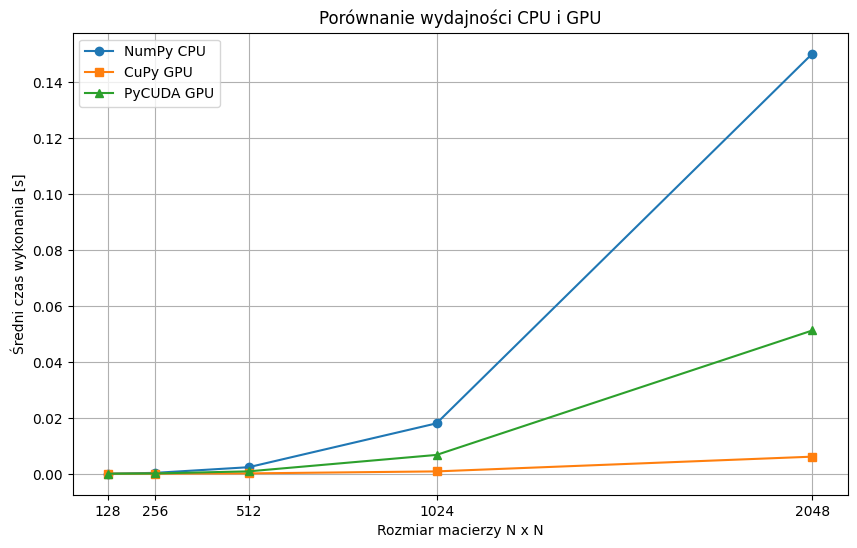

In [ ]:
import numpy as np
import cupy as cp
import time
import matplotlib.pyplot as plt

cp.cuda.Device(0).use()

import pycuda.driver as cuda
import pycuda.autoprimaryctx
from pycuda.compiler import SourceModule

sizes = [128, 256, 512, 1024, 2048]
repeats = 3

cpu_times = []
cupy_times = []
pycuda_times = []

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    float sum = 0.0f;

    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }

        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

block_size = (32, 32, 1)

for N in sizes:
    print(f"\nRozmiar macierzy: {N}x{N}")

    A_cpu = np.random.rand(N, N).astype(np.float32)
    B_cpu = np.random.rand(N, N).astype(np.float32)

    np.matmul(A_cpu, B_cpu)

    times = []

    for i in range(repeats):
        start = time.perf_counter()
        C_cpu = np.matmul(A_cpu, B_cpu)
        end = time.perf_counter()

        times.append(end - start)

    cpu_time = np.mean(times)
    cpu_times.append(cpu_time)

    A_cupy = cp.asarray(A_cpu)
    B_cupy = cp.asarray(B_cpu)

    cp.matmul(A_cupy, B_cupy)
    cp.cuda.Stream.null.synchronize()

    times = []

    for i in range(repeats):
        start = time.perf_counter()
        C_cupy = cp.matmul(A_cupy, B_cupy)
        cp.cuda.Stream.null.synchronize()
        end = time.perf_counter()

        times.append(end - start)

    cupy_time = np.mean(times)
    cupy_times.append(cupy_time)

    C_cupy_cpu = cp.asnumpy(C_cupy)

    C_pycuda = np.empty((N, N), dtype=np.float32)

    A_gpu = cuda.mem_alloc(A_cpu.nbytes)
    B_gpu = cuda.mem_alloc(B_cpu.nbytes)
    C_gpu = cuda.mem_alloc(C_pycuda.nbytes)

    cuda.memcpy_htod(A_gpu, A_cpu)
    cuda.memcpy_htod(B_gpu, B_cpu)

    grid_size = (
        (N + block_size[0] - 1) // block_size[0],
        (N + block_size[1] - 1) // block_size[1],
        1
    )

    matrixMul(
        A_gpu, B_gpu, C_gpu, np.int32(N),
        block=block_size,
        grid=grid_size
    )
    cuda.Context.synchronize()

    times = []

    for i in range(repeats):
        start = time.perf_counter()

        matrixMul(
            A_gpu, B_gpu, C_gpu, np.int32(N),
            block=block_size,
            grid=grid_size
        )

        cuda.Context.synchronize()
        end = time.perf_counter()

        times.append(end - start)

    pycuda_time = np.mean(times)
    pycuda_times.append(pycuda_time)

    cuda.memcpy_dtoh(C_pycuda, C_gpu)

    cupy_correct = np.allclose(
        C_cpu, C_cupy_cpu, rtol=1e-3, atol=1e-3
    )

    pycuda_correct = np.allclose(
        C_cpu, C_pycuda, rtol=1e-3, atol=1e-3
    )

    print(f"CPU (NumPy):  {cpu_time:.6f} s")
    print(f"GPU (CuPy):   {cupy_time:.6f} s")
    print(f"GPU (PyCUDA): {pycuda_time:.6f} s")
    print(f"CuPy przyspieszenie: {cpu_time / cupy_time:.2f}x")
    print(f"PyCUDA przyspieszenie: {cpu_time / pycuda_time:.2f}x")

    A_gpu.free()
    B_gpu.free()
    C_gpu.free()

    del A_cupy, B_cupy, C_cupy

plt.figure(figsize=(10, 6))

plt.plot(sizes, cpu_times, marker="o", label="NumPy CPU")
plt.plot(sizes, cupy_times, marker="s", label="CuPy GPU")
plt.plot(sizes, pycuda_times, marker="^", label="PyCUDA GPU")

plt.xlabel("Rozmiar macierzy N x N")
plt.ylabel("Średni czas wykonania [s]")
plt.title("Porównanie wydajności CPU i GPU")
plt.xticks(sizes)
plt.legend()
plt.grid(True)
plt.show()

cupy_speedup = [
    cpu_times[i] / cupy_times[i] for i in range(len(sizes))
]

pycuda_speedup = [
    cpu_times[i] / pycuda_times[i] for i in range(len(sizes))
]

